# Exploratory Data Analysis

Looks at the pre-existing jeepney networks to settle design decisions the algorithm depends on before its parameters are fixed:

- **Route overlaps** - how much of the road carries more than one route, and where.
- **Commuter flows** - how many people each stop and route can reach, using route
  catchments over the high resolution population grid instead of an estimated demand
  matrix.
- **Capacity constraints** - what the stops cost to build, and how MAX_DEGREE and
  MAX_BUDGET should be set per city.

Most of the code is in `src/analysis` so it can be reused to score the GA output later.

In [1]:
%load_ext autoreload
%reload_ext autoreload
%matplotlib inline

import os
import pathlib
import sys

sys.path.insert(0, os.path.abspath("../src"))

import numpy as np
import pandas as pd
from IPython.display import display

from config.config import FITNESS_WEIGHTS, MAX_BUDGET, MAX_DEGREE, STOP_SIZES, WALKING_DISTANCES

from analysis import figures
from analysis.capacity import (LTA_SHELTER_LADDER, capex_from_catchment,
                               capex_under, degree_thresholds)
from analysis.catchment import PopulationGrid, apportioned_catchments, summarize
from analysis.original_network import build_road_reference, load_original_network
from analysis.overlap import overlap_profile

In [ ]:
CITIES = ["Makati", "Manila", "Taguig"] # Mandaluyong

FIGURE_DIR = pathlib.Path("../plots/eda")
TABLE_DIR = pathlib.Path("../data/eda")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Catchment radius for the per-stop figures. 550m is the middle of WALKING_DISTANCES
REFERENCE_RADIUS = 550

print("walking distances:", WALKING_DISTANCES)
print("fitness weights  :", FITNESS_WEIGHTS)

walking distances: [300, 550, 800]
fitness weights  : {'w_cov': 0.2, 'w_int': 0.1, 'w_ext': 0.1, 'w_vul': 0.2, 'w_rob': 0.2, 'w_red': 0.2}


## Loading the Existing Networks

In [3]:
networks = {}
stop_graphs = {}

for city in CITIES:
    network, stop_graph = load_original_network(city)
    networks[city] = network
    stop_graphs[city] = stop_graph
    print(f"{city:12s} {len(network.routes):4d} routes  "
          f"{network.graph.number_of_nodes():4d} stops  "
          f"{network.graph.number_of_edges():5d} edges")

Makati         50 routes   138 stops    434 edges
Manila        307 routes   556 stops   3197 edges
Taguig         24 routes   108 stops    428 edges


In [ ]:
# which road segments jeepneys are allowed on, and how long each one is.
road_reference = {}

for city in CITIES:
    total_distance, allowed_edge, edge_len = build_road_reference(stop_graphs[city])
    road_reference[city] = (total_distance, allowed_edge, edge_len)
    print(f"{city:12s} allowed road {total_distance / 1000:8.1f} km")

Makati       allowed road    136.4 km
Manila       allowed road    318.1 km


Taguig       allowed road    179.6 km


## Route Overlaps

In [5]:
overlaps = {city: overlap_profile(networks[city], road_reference[city][2])
            for city in CITIES}

pd.DataFrame(overlaps).T

,Serviced Road Length (km),Exactly 1 Route (share),Exactly 2 Routes (share),3+ Routes (share),Max Routes On One Arc,Mean Routes Per Arc
Makati,67.209658,0.344582,0.262888,0.392530,9.0,2.659958
Manila,242.835449,0.175292,0.145837,0.678871,107.0,12.581985
Taguig,76.921944,0.287450,0.243263,0.469287,6.0,2.576208


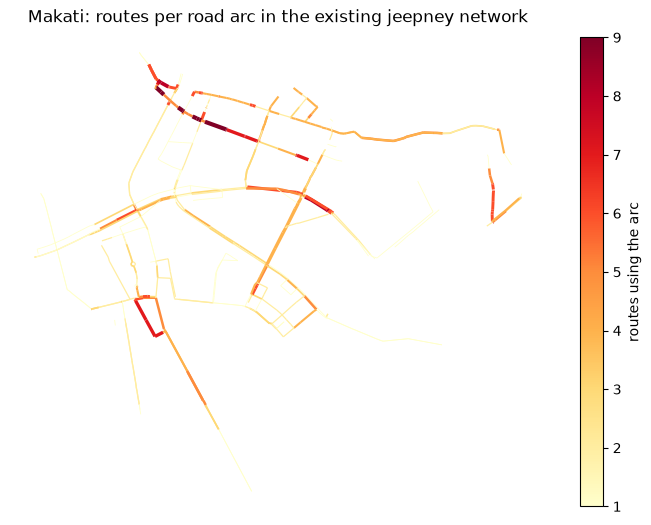

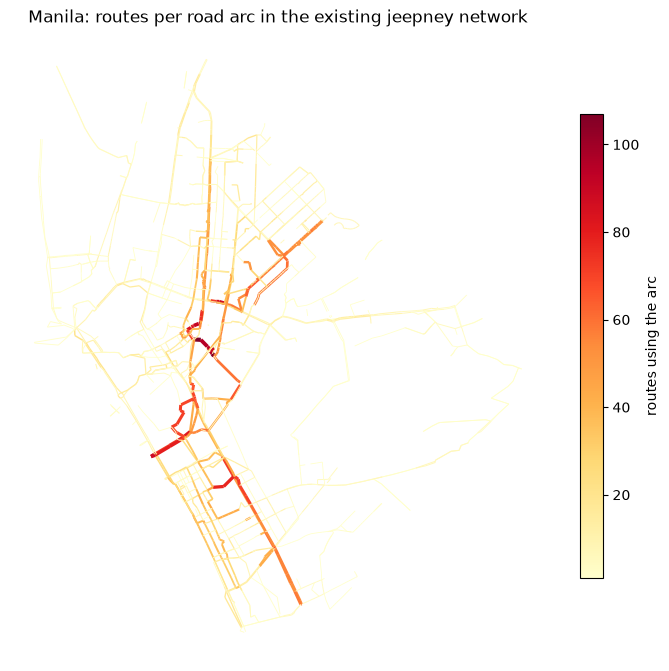

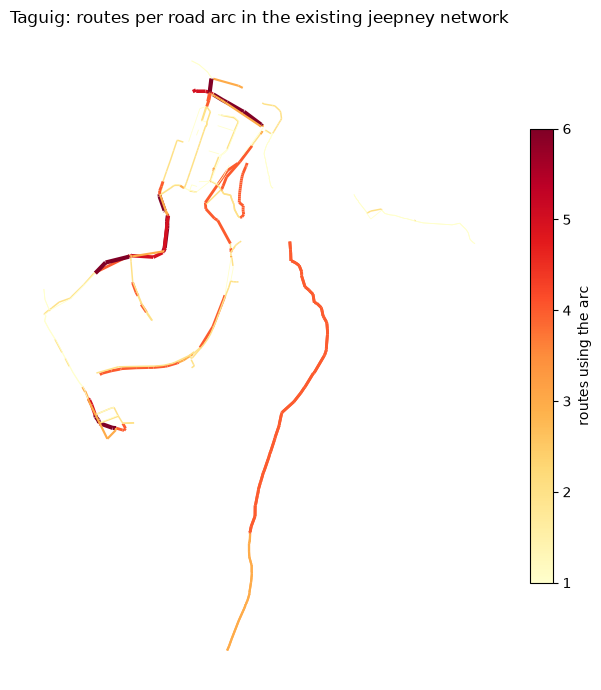

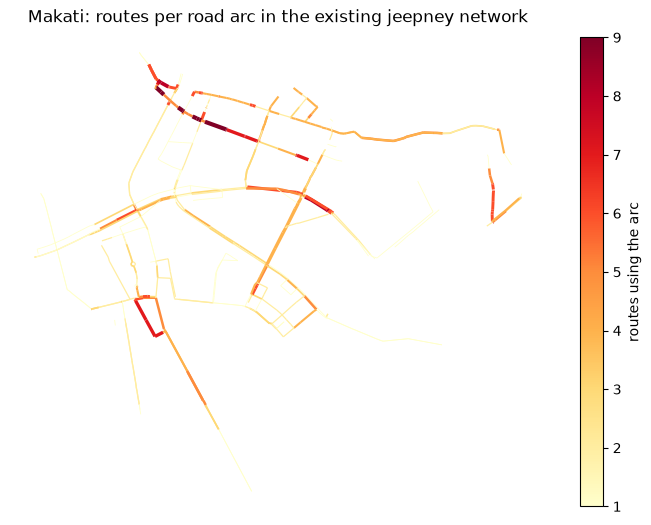

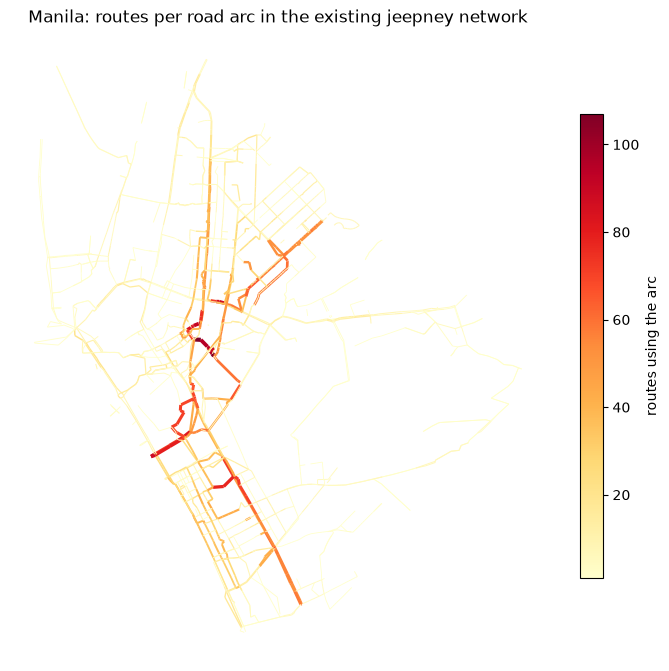

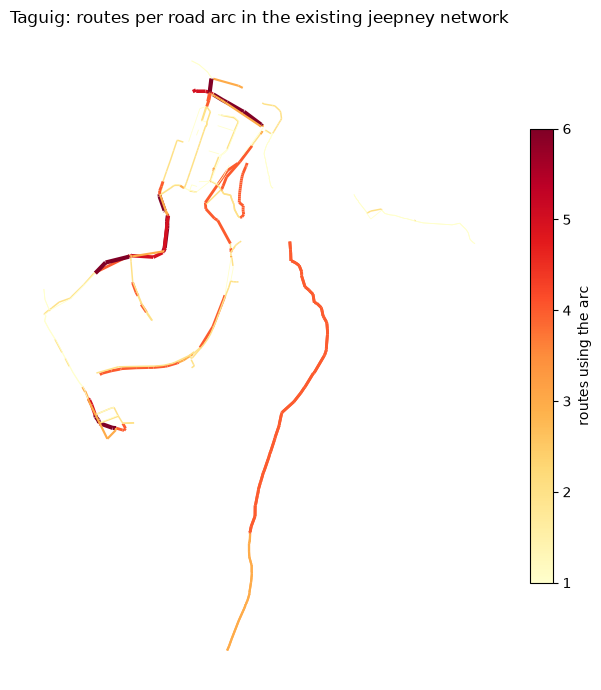

In [ ]:
for city in CITIES:
    display(figures.plot_overlap_map(
        networks[city], stop_graphs[city], road_reference[city][2], city,
        FIGURE_DIR / f"overlap_map_{city.lower()}.png"))

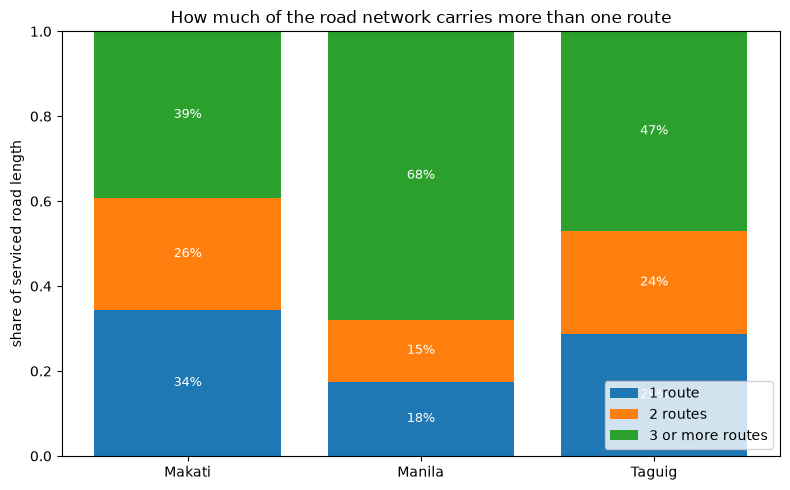

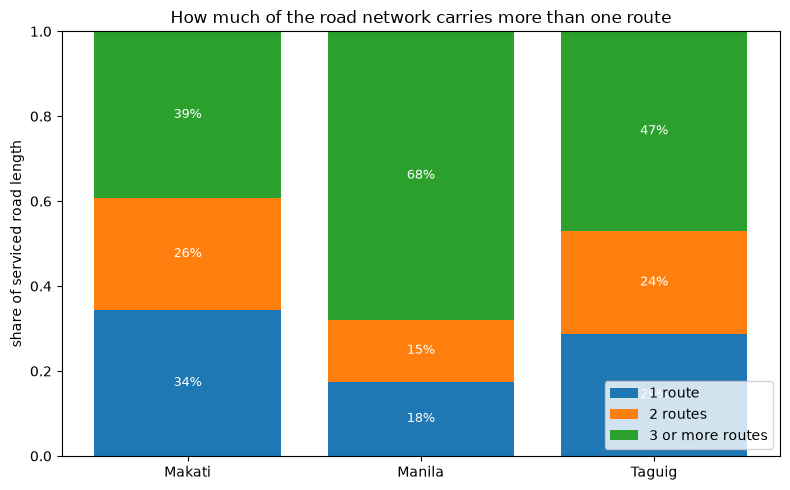

In [7]:
figures.plot_overlap_profile(overlaps, FIGURE_DIR / "overlap_profile.png")

## Commuter Flows as Route Catchments

A stop's demand is the population living within walking distance of it, comes from Meta's High Resolution Population
Density grid.

- **Raw catchment** - everyone within the radius. For "can these people reach a jeepney at all," but it counts the same resident once per stop they could walk to.
- **Apportioned catchment** - each grid cell's population split among the stops that can serve it, so per-stop figures sum to the population actually reached. For how busy a single stop is.

In [8]:
radius_rows = {city: [summarize(networks[city], city, radius)
                      for radius in WALKING_DISTANCES]
               for city in CITIES}

pd.DataFrame(
    [row for rows in radius_rows.values() for row in rows],
    index=pd.MultiIndex.from_tuples(
        [(city, row["Radius (m)"]) for city, rows in radius_rows.items() for row in rows],
        names=["city", "radius"]),
)[["City Population", "Population Reached", "Population Reached (share)",
   "Catchment Overlap Factor"]]

City Population  Population Reached  \
city   radius                                        
Makati 300        4.181831e+05        1.735167e+05   
       550        4.181831e+05        2.351298e+05   
       800        4.181831e+05        2.596151e+05   
Manila 300        1.609726e+06        1.215124e+06   
       550        1.609726e+06        1.480298e+06   
       800        1.609726e+06        1.545575e+06   
Taguig 300        9.245446e+05        3.065760e+05   
       550        9.245446e+05        5.335530e+05   
       800        9.245446e+05        6.744679e+05   

               Population Reached (share)  Catchment Overlap Factor  
city   radius                                                        
Makati 300                       0.414930                  3.686417  
       550                       0.562265                  8.605345  
       800                       0.620817                 14.998263  
Manila 300                       0.754864                  4.958242  
       550                       0.919596                 12.952217  
       800                       0.960148                 25.818006  
Taguig 300                       0.331597                  1.949301  
       550                       0.577098                  3.447187  
       800                       0.729514                  5.308786

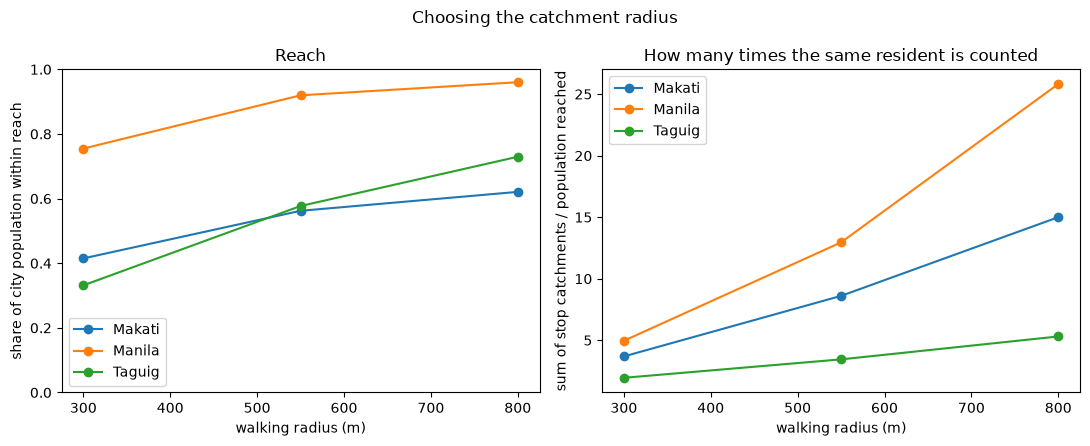

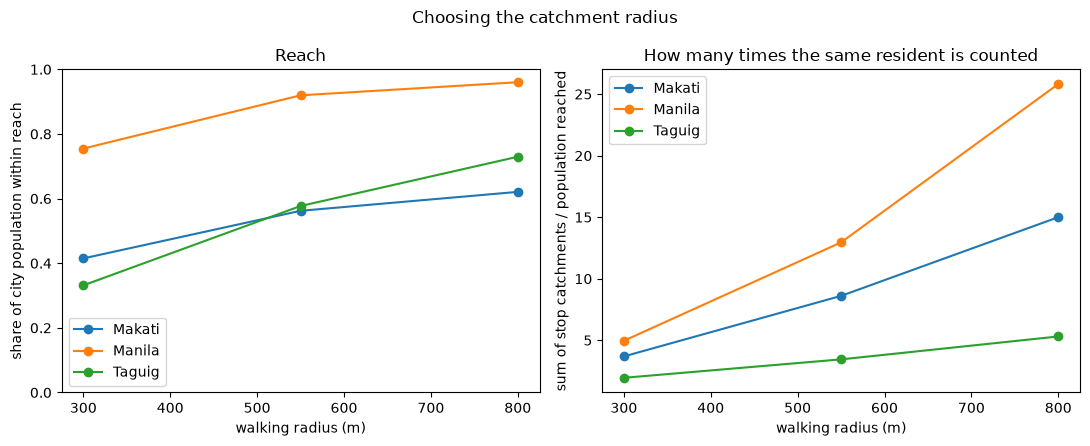

In [ ]:
# Widening the radius buys reach but costs double counting
figures.plot_catchment_overlap(radius_rows, FIGURE_DIR / "catchment_radius.png")

In [10]:
grids = {city: PopulationGrid(city) for city in CITIES}
apportioned = {city: apportioned_catchments(networks[city], grids[city], REFERENCE_RADIUS)
               for city in CITIES}

for city in CITIES:
    values = np.array(list(apportioned[city].values()))
    print(f"{city:12s} apportioned sum {values.sum():12,.0f}  per stop: "
          f"mean {values.mean():8,.0f}  median {np.median(values):8,.0f}  "
          f"max {values.max():8,.0f}")

Makati       apportioned sum      235,130  per stop: mean    1,704  median    1,533  max    9,507
Manila       apportioned sum    1,480,298  per stop: mean    2,662  median    1,319  max   25,228
Taguig       apportioned sum      533,553  per stop: mean    4,940  median    4,293  max   18,848


## Capacity Constraints

`fitness_capex_cost` sizes a stop from its **degree**, which only makes sense if degree tracks how busy the stop is.

In [11]:
# Does degree say anything about how many people a stop serves?
for city in CITIES:
    degrees = np.array([networks[city].graph.degree(stop) for stop in apportioned[city]])
    population = np.array(list(apportioned[city].values()))
    print(f"{city:12s} pearson r = {np.corrcoef(degrees, population)[0, 1]:+.3f}")

Makati       pearson r = +0.103
Manila       pearson r = -0.118
Taguig       pearson r = +0.044


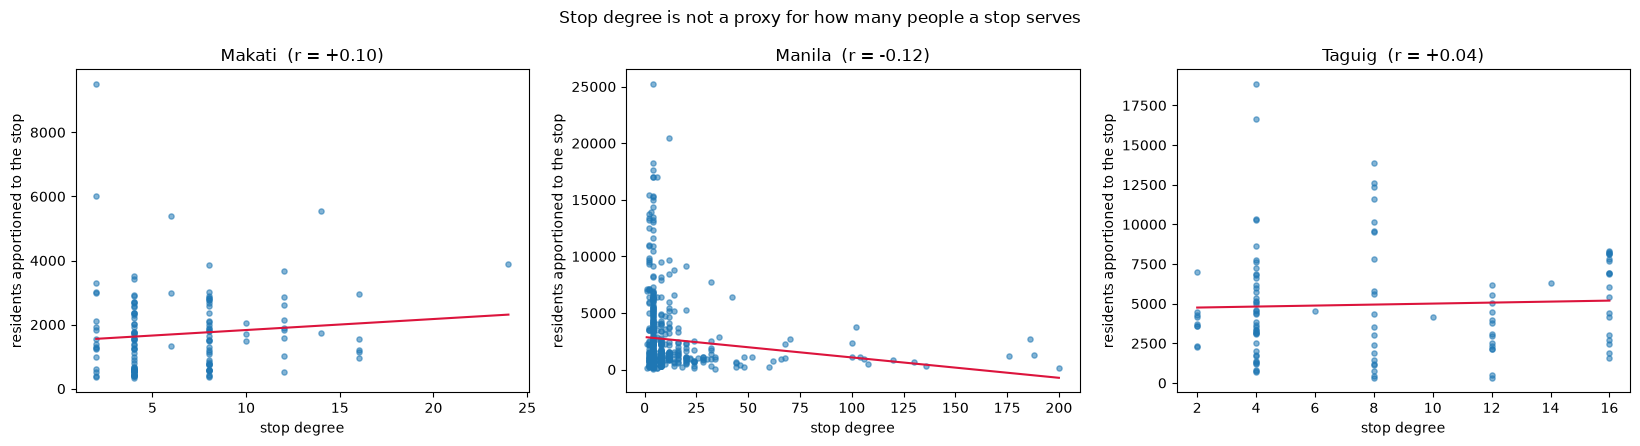

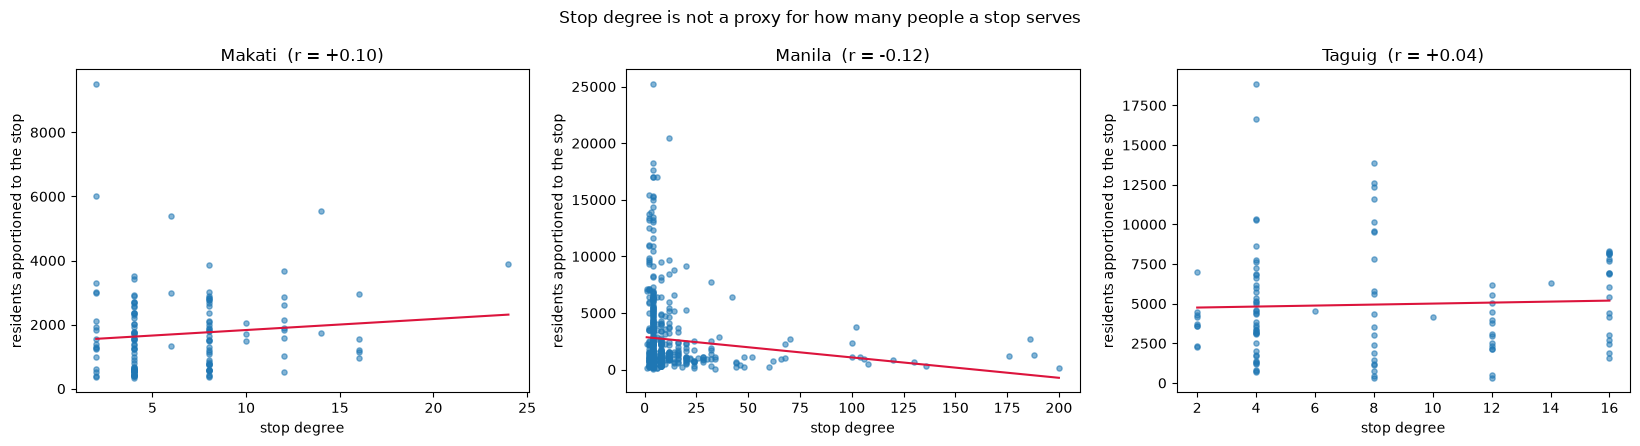

In [12]:
samples = {city: ([networks[city].graph.degree(stop) for stop in apportioned[city]],
                  list(apportioned[city].values()))
           for city in CITIES}

figures.plot_degree_vs_catchment(samples, FIGURE_DIR / "degree_vs_catchment.png")

### Stop Sizing

In [13]:
print("configured STOP_SIZES:", STOP_SIZES)

pd.DataFrame([{"boardings per peak hour": "150 or less" if upper == 150
                                          else ("above 1000" if upper == float("inf") else upper),
               "length (m)": length,
               "width (m)": width,
               "area (sqm)": length * width}
              for upper, length, width in LTA_SHELTER_LADDER])

configured STOP_SIZES: [27.0, 40.5, 54.0]


,boardings per peak hour,length (m),width (m),area (sqm)
0,150 or less,6,3,18
1,200,9,3,27
2,300,12,3,36
3,400,15,3,45
4,500,18,3,54
5,600,21,3,63
6,700,24,3,72
7,800,27,3,81
8,900,30,3,90
9,1000,33,3,99


In [ ]:
PEAK_BOARDING_RATE = 0.05
BOARDING_RATE_SWEEP = [0.02, 0.05, 0.10, 0.20]

capex_options = {}
for city in CITIES:
    network = networks[city]
    config_cost, _ = capex_under(network)
    terciles = degree_thresholds(network)
    tercile_cost, _ = capex_under(network, max_degree=terciles)
    catchment_cost, _ = capex_from_catchment(apportioned[city], PEAK_BOARDING_RATE)

    capex_options[city] = {
        "sized by degree, config thresholds": config_cost,
        "sized by degree, per-city terciles": tercile_cost,
        f"sized to catchment, {PEAK_BOARDING_RATE:.0%} board in peak hour": catchment_cost,
    }
    print(f"{city:12s} config {config_cost / 1e6:7.1f}M  "
          f"terciles {tercile_cost / 1e6:7.1f}M {terciles}  "
          f"catchment {catchment_cost / 1e6:7.1f}M")

print(f"\nconfigured MAX_BUDGET: {MAX_BUDGET / 1e6:.0f}M   MAX_DEGREE: {MAX_DEGREE}")

Makati       config   173.1M  terciles   135.3M [4, 8, 999999]  catchment    74.3M
Manila       config   696.7M  terciles   560.2M [4, 8, 999999]  catchment   387.6M
Taguig       config   140.6M  terciles   116.4M [4, 8, 999999]  catchment   105.8M

configured MAX_BUDGET: 200M   MAX_DEGREE: [3, 5, 999999]


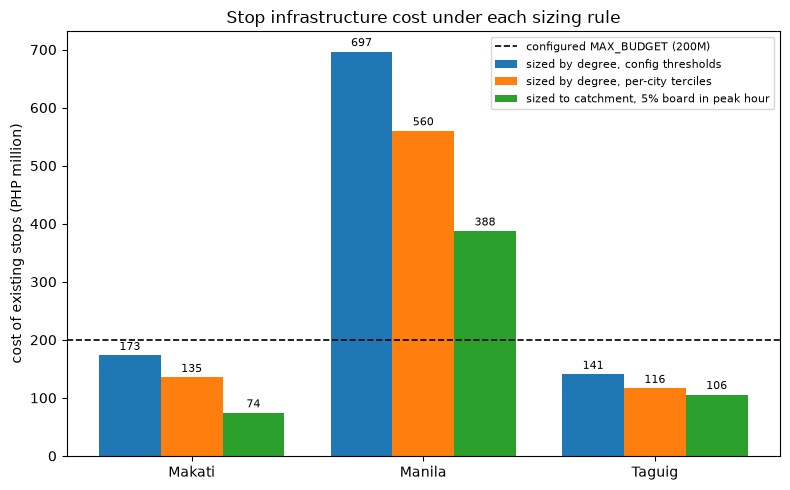

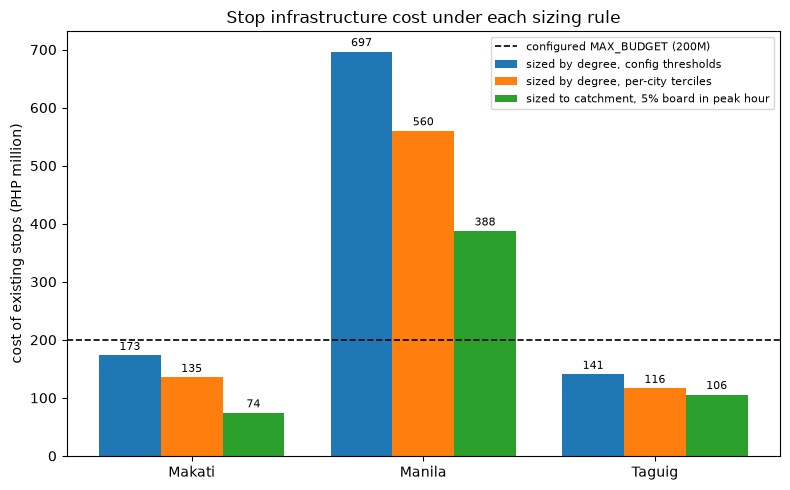

In [15]:
figures.plot_capex_options(capex_options, MAX_BUDGET, FIGURE_DIR / "capex_options.png")

In [16]:
# How much the stop cost depends on the peak-hour boarding rate assumed
pd.DataFrame(
    {city: {f"{rate:.0%} board in peak hour":
            capex_from_catchment(apportioned[city], rate)[0] / 1e6
            for rate in BOARDING_RATE_SWEEP}
     for city in CITIES}).round(1)

,Makati,Manila,Taguig
2% board in peak hour,69.8,300.4,62.7
5% board in peak hour,74.3,387.6,105.8
10% board in peak hour,104.8,531.2,168.8
20% board in peak hour,162.8,768.6,244.9


## Baseline Comparison

In [17]:
from analysis.baseline import baseline_table

baseline = pd.DataFrame(baseline_table(CITIES, FITNESS_WEIGHTS)).set_index("City")
baseline.to_csv(TABLE_DIR / "original_network_baseline.csv")
baseline.T

City,Makati,Manila,Taguig
Routes,50,307,24
Lines,25,154,12
Stops,138,556,108
Route Edges,434,3197,428
Transport Stops,38,147,2
Transport Stop Share,0.275362,0.264388,0.018519
Total Route Length (km),248.884923,4083.04771,279.442205
Mean Route Length (km),4.977698,13.29983,11.643425
Median Route Length (km),3.752629,11.400959,8.333681
Shortest Route (km),0.159737,0.849008,2.732243


## Design Inputs

In [18]:
rows = []
for city in CITIES:
    reference = next(r for r in radius_rows[city] if r["Radius (m)"] == REFERENCE_RADIUS)
    row = {"City": city,
           "Degree Terciles": degree_thresholds(networks[city]),
           "Reference Radius (m)": REFERENCE_RADIUS}
    row.update({k: v for k, v in reference.items() if k != "Radius (m)"})
    row.update(overlaps[city])
    row.update(capex_options[city])
    rows.append(row)

design_inputs = pd.DataFrame(rows).set_index("City")
design_inputs.to_csv(TABLE_DIR / "eda_design_inputs.csv")
design_inputs.T

City,Makati,Manila,Taguig
Degree Terciles,"[4, 8, 999999]","[4, 8, 999999]","[4, 8, 999999]"
Reference Radius (m),550,550,550
City Population,418183.133328,1609726.413263,924544.648764
Population Reached,235129.791225,1480297.650924,533552.955606
Population Reached (share),0.562265,0.919596,0.577098
Sum Of Stop Catchments,2023373.033977,19173135.685225,1839257.075347
Catchment Overlap Factor,8.605345,12.952217,3.447187
Stop Catchment Mean,14662.123435,34484.056988,17030.158105
Stop Catchment Median,13696.740904,34083.953188,16186.72237
Stop Catchment Min,739.35187,137.084216,803.417467
